In [1]:
import os
import math
import pandas as pd
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

In [2]:
# Function to calculate entropy of file content
def dict_calculate_entropy(content: bytes, base: float = 2) -> dict:
    """
    Calculate Shannon entropy and normalized Shannon entropy (metric)
    for the given bytes content.

    Parameters:
    - content (bytes): The input data to calculate entropy for.
    - base (float): Logarithm base for entropy calculation (default: 2).

    Returns:
    - dict: Dictionary with keys 'shannon' and 'metric' containing the entropy values.
    """
    if not content:
        return {'shannon': 0.0, 'metric': 0.0}

    def p(i):
        return content.count(i) / len(content)

    H = 0.0
    for i in set(content):
        prob = p(i)
        H -= prob * math.log(prob, base)

    metric = H / math.log(256, base)  # Normalize entropy

    return {'shannon': H, 'metric': metric}

def dict_analyze_file(path_file):
    try:
        with open(path_file, 'rb') as f:
            content = f.read()
        size = os.path.getsize(path_file)
        dict_entropy = dict_calculate_entropy(content)

        byte_counts = {}
        for b in content:
            if b in byte_counts:
                byte_counts[b] += 1
            else:
                byte_counts[b] = 1

        return {
            'filename': os.path.basename(path_file),
            'size_bytes': size,
            'entropy': dict_entropy['shannon'],
            'normalized_entropy': dict_entropy['metric'],
            'byte_counts': byte_counts  # dict of counts
        }
    except Exception as e:
        return {
            'filename': os.path.basename(path_file),
            'size_bytes': None,
            'entropy': None,
            'byte_counts': {},
            'error': str(e)
        }

# Process all files in a directory, preparing normalized data
def process_directory(path_directory):
    list_results = []
    for string_filename in os.listdir(path_directory):
        path_file = os.path.join(path_directory, string_filename)
        if os.path.isfile(path_file):
            dict_result = dict_analyze_file(path_file)
            list_results.append(dict_result)
    df_summary = pd.DataFrame(
        [{'filename': r['filename'], 'size_bytes': r['size_bytes'],
          'entropy': r['entropy'],
          'normalized_entropy': r['normalized_entropy'],
          'error': r.get('error', None)}
         for r in list_results])

    # Prepare DataFrame for normalized byte frequency histogram
    list_byte_rows = []
    for r in list_results:
        for byte_value, count in r['byte_counts'].items():
            list_byte_rows.append(\
                {'filename': r['filename'], 'byte_value': byte_value,
                 'count': count})
    df_bytes = pd.DataFrame(list_byte_rows)

    # Normalize counts by file size per file
    df_bytes = df_bytes.merge(
        df_summary[['filename', 'size_bytes']], on='filename', how='left')
    df_bytes['normalized_count'] = df_bytes['count'] / df_bytes['size_bytes']

    return df_summary, df_bytes


In [3]:
path_data_set = os.path.join('..', 'Data', 'Original')
path_results = os.path.join('..', 'Data', 'cache_data', 'images')
df_summary, df_bytes = process_directory(path_data_set)
df_summary

,filename,size_bytes,entropy,normalized_entropy,error
0,nature.gif,185727,7.637820,0.954728,None
1,Vue_de_la_Buena_Vista.jpg,70296,7.971416,0.996427,None
2,egypt.mp4,1511673,7.999071,0.999884,None
3,all_black.png,2778,4.213494,0.526687,None
4,bbc_clock.mp3,121753,7.966743,0.995843,None
5,The_Picture_of_Dorian_Gray.txt,465592,4.621325,0.577666,None
6,Around_the_World_in_Eighty_Days.txt,403521,4.713540,0.589192,None
7,Zero_File.pdf,7523,7.404768,0.925596,None
8,bbc_peregrine_falcon.wav,751800,5.214563,0.651820,None


In [4]:
df_bytes

,filename,byte_value,count,size_bytes,normalized_count
0,nature.gif,71,583,185727,0.003139
1,nature.gif,73,707,185727,0.003807
2,nature.gif,70,658,185727,0.003543
3,nature.gif,56,712,185727,0.003834
4,nature.gif,57,488,185727,0.002628
...,...,...,...,...,...
1833,bbc_peregrine_falcon.wav,190,555,751800,0.000738
1834,bbc_peregrine_falcon.wav,217,518,751800,0.000689
1835,bbc_peregrine_falcon.wav,193,475,751800,0.000632
1836,bbc_peregrine_falcon.wav,182,518,751800,0.000689


/var/folders/lt/rbb0s8nn4wzbjftxx8s6bqx40000gp/T/ipykernel_14468/2657329002.py:25: DeprecationWarning:


Support for Kaleido versions less than 1.0.0 is deprecated and will be removed after September 2025.
Please upgrade Kaleido to version 1.0.0 or greater (`pip install 'kaleido>=1.0.0'` or `pip install 'plotly[kaleido]'`).


/var/folders/lt/rbb0s8nn4wzbjftxx8s6bqx40000gp/T/ipykernel_14468/2657329002.py:26: DeprecationWarning:


Support for Kaleido versions less than 1.0.0 is deprecated and will be removed after September 2025.
Please upgrade Kaleido to version 1.0.0 or greater (`pip install 'kaleido>=1.0.0'` or `pip install 'plotly[kaleido]'`).




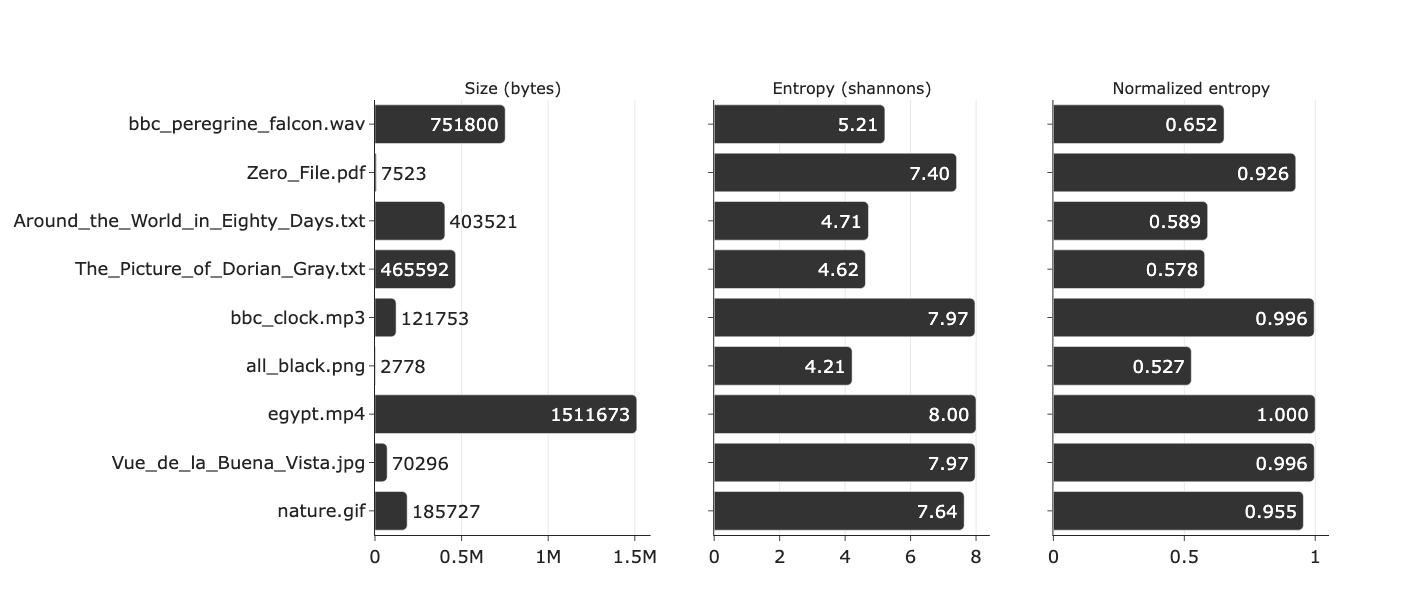

In [5]:
fig = make_subplots(
    rows=1, cols=3, shared_yaxes=True, vertical_spacing=0.02,
    subplot_titles=['Size (bytes)', 'Entropy (shannons)', 'Normalized entropy'])

fig.add_trace(
    go.Bar(y=df_summary['filename'], x=df_summary['size_bytes'],
           orientation='h', text=df_summary['size_bytes']),
    row=1, col=1)

fig.add_trace(
    go.Bar(y=df_summary['filename'], x=df_summary['entropy'], orientation='h',
           text=df_summary['entropy'], texttemplate='%{text:.2f}'),
    row=1, col=2)

fig.add_trace(
    go.Bar(y=df_summary['filename'], x=df_summary['normalized_entropy'],
           orientation='h', text=df_summary['normalized_entropy'],
           texttemplate='%{text:.3f}'),
    row=1, col=3)

fig.update_traces(marker_color='#333333')
fig.update_layout(height=600, width=1500, showlegend=False,
                  template='simple_white', barcornerradius=5, font_size=18)
fig.update_xaxes(showgrid=True)
fig.write_image(os.path.join(path_results, 'data_set_summary.pdf'))
fig.write_image(os.path.join(path_results, 'data_set_summary.svg'), scale=3)
fig.show()

/var/folders/lt/rbb0s8nn4wzbjftxx8s6bqx40000gp/T/ipykernel_14468/265461135.py:13: DeprecationWarning:


Support for Kaleido versions less than 1.0.0 is deprecated and will be removed after September 2025.
Please upgrade Kaleido to version 1.0.0 or greater (`pip install 'kaleido>=1.0.0'` or `pip install 'plotly[kaleido]'`).


/var/folders/lt/rbb0s8nn4wzbjftxx8s6bqx40000gp/T/ipykernel_14468/265461135.py:14: DeprecationWarning:


Support for Kaleido versions less than 1.0.0 is deprecated and will be removed after September 2025.
Please upgrade Kaleido to version 1.0.0 or greater (`pip install 'kaleido>=1.0.0'` or `pip install 'plotly[kaleido]'`).




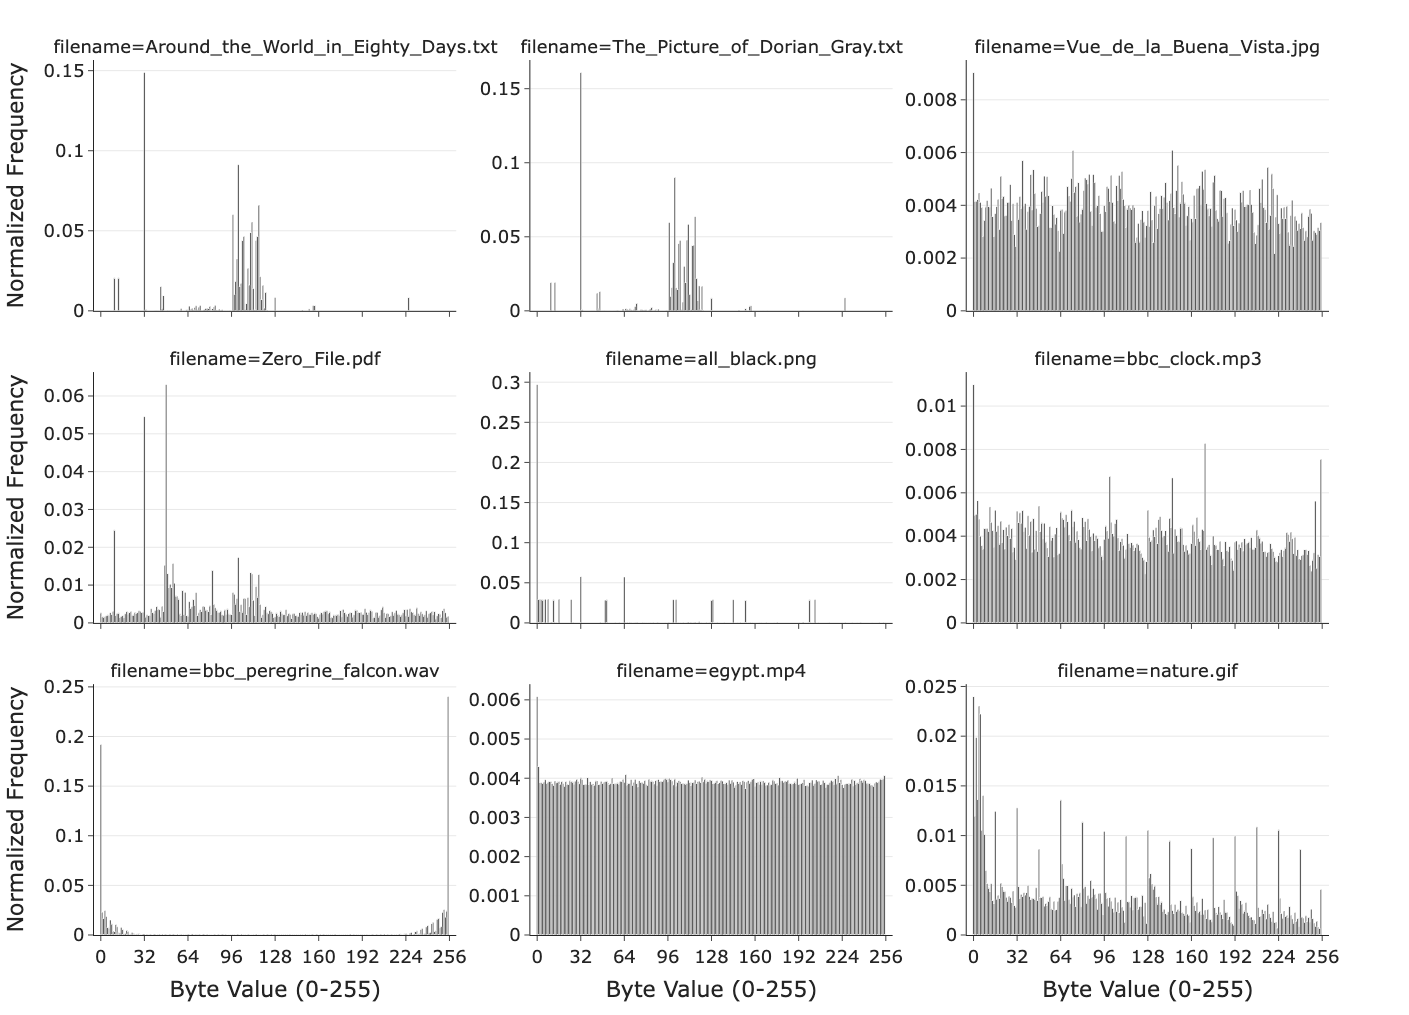

In [6]:
fig = px.bar(
    df_bytes, x='byte_value', y='normalized_count', facet_col='filename',
    facet_col_wrap=3, template="simple_white", facet_col_spacing=0.06,
    category_orders={"filename": sorted(df_bytes['filename'].unique())},
    labels={'byte_value': 'Byte Value (0-255)',
            'normalized_count': 'Normalized Frequency'})

fig.update_traces(marker_color='#333333')
fig.update_xaxes(tickmode="linear", tick0=0, dtick=32, tickangle=0,
                 range=[-5, 261])
fig.update_yaxes(matches=None, showgrid=True, showticklabels=True)
fig.update_layout(bargap=0.05, height=1000, width=1500, font_size=18)
fig.write_image(os.path.join(path_results, 'data_set_histogram.pdf'))
fig.write_image(os.path.join(path_results, 'data_set_histogram.svg'), scale=3)
fig.show()